# 03 — Korelasi Statis, Beta & Korelasi Asimetris

**Phase 3/7 — Static correlation.** Phase ini memetakan seberapa kuat tiap seri Core bergerak bersama IHSG, dan apakah hubungan itu konsisten antar-periode, antar-frekuensi (harian vs mingguan), dan antara pasar turun vs naik. Regresi multifaktor memisahkan kontribusi tiap seri saat seri lain dikendalikan. Ini penting karena STI, KLCI, EEM, dan Hang Seng membawa banyak informasi yang sama.

**Semua hasil di sini DESKRIPTIF: asosiasi in-sample, bukan sinyal dan bukan sebab-akibat.** Tidak ada pemilihan ulang seri. Teknik dan parameter mengikuti README "Rencana teknik per phase (dikunci)". Tabel dengan banyak uji melaporkan p-value terkoreksi Benjamini–Hochberg (`*_bh`). Brent selalu berlabel "dipilih dengan pengetahuan periode uji".

In [1]:
import json

import pandas as pd
from IPython.display import Markdown, display

from src import analysis as an
from src import plots
from src import preprocess as pp
from src.config import load_config, output_dir, series_table, target_usd_id
from src.data_loader import close_panel, load_prices

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

cfg = load_config()
series = series_table(cfg, groups=("target", "core", "tools"))
target_id = cfg["project"]["target_id"]
usd_id = target_usd_id(cfg)
fx_id = cfg["usdidr_retest"]["id"]
core = [s["id"] for s in cfg["core"]]
names = dict(zip(series["id"], series["name"])) | {usd_id: f"{cfg['target'][0]['name']} dalam USD"}
labels = series.set_index("id")["label"].rename("label")
transforms = dict(zip(series["id"], series["transform"]))

dec2 = json.loads((output_dir(cfg, "reports", "phase2") / "decisions.json").read_text())
periods = an.period_bounds(cfg, dec2["analysis_start"])
proc = output_dir(cfg, "data/processed")
prices_clean = pd.read_parquet(proc / "prices_clean.parquet")
daily = pd.read_parquet(proc / "daily_pair_returns.parquet")
weekly = pd.read_parquet(proc / "weekly_returns.parquet")
target_usd = pd.read_parquet(proc / "target_usd.parquet")[usd_id]
print("Periode:", {k: f"{v[0]} s/d {v[1] or 'akhir data'}" for k, v in periods.items()})
print(f"Panel mingguan {weekly.shape}, return harian {len(daily):,} baris, Core = {core}")

Periode: {'penuh': '2007-01-01 s/d akhir data', 'screening': '2010-01-01 s/d 2019-12-31', 'pasca': '2020-01-01 s/d akhir data'}
Panel mingguan (1034, 13), return harian 50,104 baris, Core = ['STI', 'KLCI', 'EEM', 'SPX', 'NIFTY', 'HSI', 'VIX', 'COPPER', 'BRENT', 'USDIDR']


## 1. Korelasi tiap seri Core vs IHSG

Korelasi dihitung di tiga periode, dengan dua metode dan dua frekuensi:
- **Periode:** penuh (2007–sekarang), screening (2010–2019, periode seleksi yang dikunci), dan pasca-screening (2020–sekarang).
- **Metode:** Pearson (linier) dan Spearman (peringkat, tahan outlier).
- **Frekuensi:** harian (hari yang sama, hanya tanggal yang dua-duanya buka) dan mingguan (W-FRI).

CI 95% dihitung dengan Fisher z. Untuk Spearman, standard error dikali √1,06 (Fieller–Hartley–Pearson).

In [2]:
tab = an.correlation_table(daily, weekly, target_id, core, periods)
view = tab.assign(nilai=tab.apply(lambda r: f"{r.r:+.2f} [{r.ci_lo:+.2f}, {r.ci_hi:+.2f}]", axis=1))
pivot = view.pivot_table(index="id", columns=["frekuensi", "metode", "periode"], values="nilai", aggfunc="first")
pivot = pivot.reindex(columns=["screening", "pasca", "penuh"], level=2)
pivot[("label", "", "")] = labels.reindex(pivot.index)
pivot.loc[core]

frekuensi                harian                                                                                                                            mingguan                                              \
metode                  pearson                                                          spearman                                                           pearson                                               
periode               screening                 pasca                 penuh             screening                 pasca                 penuh             screening                 pasca                 penuh   
id                                                                                                                                                                                                                
STI        +0.53 [+0.50, +0.56]  +0.43 [+0.39, +0.47]  +0.57 [+0.55, +0.59]  +0.46 [+0.43, +0.50]  +0.29 [+0.24, +0.33]  +0.44 [+0.42, +0.47]  +0.53 [+0.46, +0.59]  +0.44 [+0.35, +0.52]  +0.54 [+0.49, +0.58]   
KLCI       +0.50 [+0.47, +0.53]  +0.41 [+0.36, +0.45]  +0.51 [+0.49, +0.53]  +0.49 [+0.46, +0.52]  +0.32 [+0.27, +0.37]  +0.44 [+0.42, +0.46]  +0.52 [+0.46, +0.58]  +0.39 [+0.30, +0.47]  +0.53 [+0.49, +0.57]   
EEM        +0.27 [+0.23, +0.30]  +0.28 [+0.23, +0.32]  +0.28 [+0.25, +0.30]  +0.21 [+0.17, +0.25]  +0.21 [+0.16, +0.25]  +0.22 [+0.19, +0.25]  +0.53 [+0.46, +0.59]  +0.51 [+0.43, +0.59]  +0.52 [+0.48, +0.57]   
SPX        +0.16 [+0.12, +0.20]  +0.23 [+0.18, +0.27]  +0.21 [+0.18, +0.23]  +0.10 [+0.06, +0.14]  +0.13 [+0.08, +0.18]  +0.13 [+0.10, +0.16]  +0.33 [+0.25, +0.41]  +0.43 [+0.34, +0.51]  +0.38 [+0.33, +0.43]   
NIFTY      +0.42 [+0.39, +0.46]  +0.42 [+0.38, +0.46]  +0.47 [+0.45, +0.49]  +0.36 [+0.33, +0.40]  +0.32 [+0.27, +0.36]  +0.37 [+0.35, +0.40]  +0.46 [+0.39, +0.53]  +0.47 [+0.38, +0.55]  +0.50 [+0.45, +0.55]   
HSI        +0.52 [+0.49, +0.55]  +0.29 [+0.25, +0.34]  +0.51 [+0.48, +0.53]  +0.48 [+0.44, +0.51]  +0.28 [+0.23, +0.33]  +0.44 [+0.42, +0.46]  +0.47 [+0.40, +0.54]  +0.29 [+0.19, +0.39]  +0.46 [+0.41, +0.51]   
VIX        -0.13 [-0.17, -0.09]  -0.16 [-0.21, -0.11]  -0.15 [-0.18, -0.12]  -0.08 [-0.12, -0.04]  -0.10 [-0.15, -0.05]  -0.09 [-0.12, -0.06]  -0.28 [-0.36, -0.20]  -0.34 [-0.43, -0.24]  -0.29 [-0.35, -0.24]   
COPPER     +0.17 [+0.13, +0.21]  +0.19 [+0.15, +0.24]  +0.22 [+0.19, +0.24]  +0.11 [+0.07, +0.15]  +0.15 [+0.10, +0.20]  +0.15 [+0.12, +0.18]  +0.28 [+0.20, +0.36]  +0.26 [+0.16, +0.36]  +0.31 [+0.25, +0.36]   
BRENT      +0.12 [+0.08, +0.16]  +0.11 [+0.06, +0.15]  +0.15 [+0.12, +0.18]  +0.08 [+0.04, +0.12]  +0.09 [+0.03, +0.14]  +0.11 [+0.08, +0.14]  +0.20 [+0.12, +0.29]  +0.17 [+0.06, +0.27]  +0.20 [+0.14, +0.26]   
USDIDR     -0.07 [-0.11, -0.03]  -0.10 [-0.15, -0.05]  -0.13 [-0.15, -0.10]  -0.10 [-0.15, -0.06]  -0.11 [-0.16, -0.06]  -0.13 [-0.16, -0.10]  -0.34 [-0.41, -0.26]  -0.39 [-0.48, -0.30]  -0.31 [-0.37, -0.25]   

frekuensi                                                                                                     label  
metode                 spearman                                                                                      
periode               screening                 pasca                 penuh                                          
id                                                                                                                   
STI        +0.47 [+0.40, +0.54]  +0.39 [+0.29, +0.48]  +0.49 [+0.44, +0.53]                                          
KLCI       +0.45 [+0.38, +0.52]  +0.37 [+0.27, +0.46]  +0.47 [+0.42, +0.52]                                          
EEM        +0.47 [+0.40, +0.54]  +0.39 [+0.29, +0.48]  +0.48 [+0.43, +0.53]                                          
SPX        +0.28 [+0.19, +0.36]  +0.29 [+0.19, +0.38]  +0.31 [+0.25, +0.37]                                          
NIFTY      +0.47 [+0.40, +0.54]  +0.39 [+0.30, +0.48]  +0.48 [+0.43, +0.53]                          

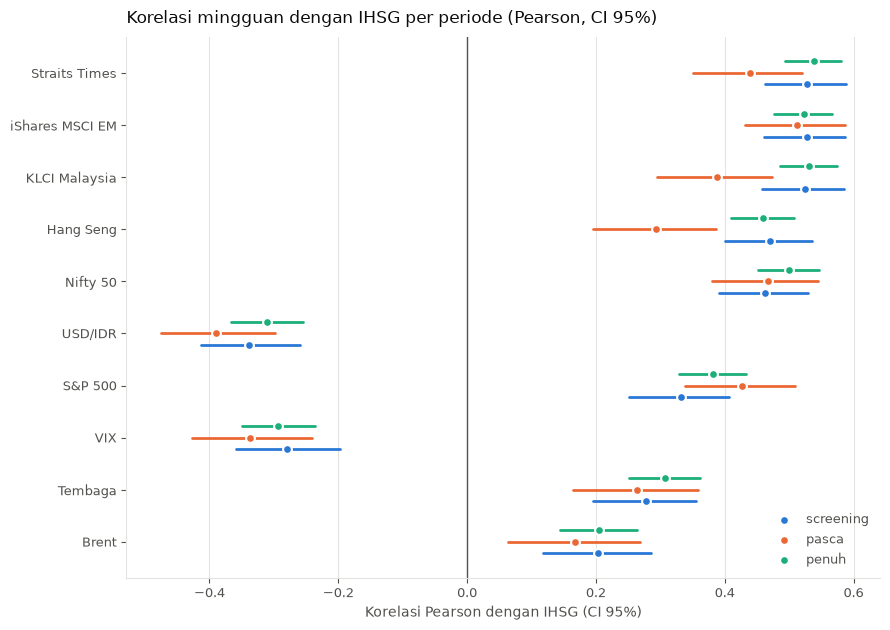

In [3]:
wk = tab[(tab["frekuensi"] == "mingguan") & (tab["metode"] == "pearson")]
fig = plots.plot_corr_by_period(wk, names, "Korelasi mingguan dengan IHSG per periode (Pearson, CI 95%)")

## 2. IHSG dalam rupiah vs IHSG dalam USD

IHSG dalam USD = IHSG / USD/IDR (bersih). Kalau korelasi IHSG dalam USD dengan pasar global lebih tinggi, berarti sebagian keterkaitan IHSG dengan dunia mengalir lewat kurs: investor asing melihat return dalam dolar.

**Catatan timing (README, Keterbatasan data):** bar harian IDR=X tutup di jam AS, sedangkan IHSG tutup 16:00 WIB. Return harian IHSG dalam USD karenanya ikut membawa pergerakan rupiah di sesi Eropa/AS, sehingga korelasi hariannya dengan seri sesi "after" bisa terlalu tinggi. Di frekuensi mingguan efek ini jauh lebih kecil.

Korelasi USD/IDR dengan IHSG dalam USD sebagian **mekanis**, karena USD/IDR adalah pembagi dalam definisi seri itu sendiri. Karena itu angka tersebut tidak ditafsirkan.

In [4]:
close_usd = prices_clean.drop(columns=[target_id]).join(target_usd, how="left")
daily_usd = pp.pair_daily_returns(close_usd, usd_id, {**transforms, usd_id: "log"})
tab_usd = an.correlation_table(daily_usd, weekly, usd_id, core, periods)
usd_cmp = an.compare_targets(tab, tab_usd, "idr", "usd")
cmp_view = usd_cmp[usd_cmp["metode"] == "pearson"].pivot_table(index="id", columns=["frekuensi", "periode"],
                                                               values=["r_idr", "r_usd", "selisih"])
cmp_view = cmp_view.reindex(columns=["screening", "pasca", "penuh"], level=2).round(2)
cmp_view.loc[core, (slice(None), "mingguan")]
print("Rata-rata |r_usd| - |r_idr| (seri non-kurs, mingguan Pearson):", an.usd_effect_text(usd_cmp, fx_id))

Rata-rata |r_usd| - |r_idr| (seri non-kurs, mingguan Pearson): pasca +0.05 (lebih kuat dalam USD); penuh +0.01 (praktis sama); screening +0.01 (praktis sama)


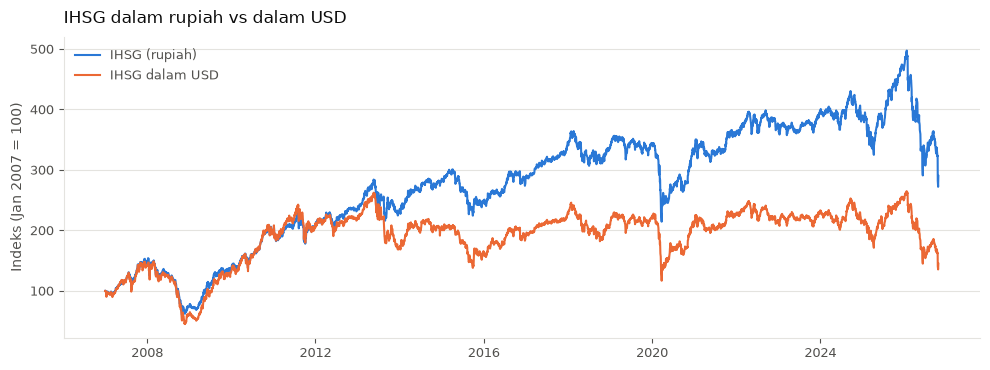

In [5]:
fig = plots.plot_idr_vs_usd(prices_clean[target_id], target_usd, "IHSG dalam rupiah vs dalam USD", names[target_id])

## 3. Seri sesi "after": korelasi harian meremehkan hubungannya

Seri yang tutup **setelah** IHSG (EEM, S&P 500, Nifty, VIX, komoditas, USD/IDR) baru bisa memengaruhi IHSG di hari bursa **berikutnya**. Korelasi di hari yang sama karena itu hanya menangkap sebagian hubungan. Di frekuensi mingguan, reaksi yang tertunda sehari sebagian besar sudah masuk ke minggu yang sama.

Pola yang diharapkan: rasio harian/mingguan untuk seri sesi "sync" (STI, KLCI, HSI) mendekati 1, sedangkan untuk seri "after" jauh di bawah 1. Phase 4 mengukur lead t → t+1 secara langsung.

In [6]:
gap = an.session_gap_table(tab, series, "screening")
display(gap.round(2))
print("Median rasio harian/mingguan per sesi (2010-2019):", gap.groupby("session")["rasio_harian_mingguan"].median().round(2).to_dict())

,name,session,harian,mingguan,rasio_harian_mingguan
id,,,,,
USDIDR,USD/IDR,after,-0.07,-0.34,0.21
VIX,VIX,after,-0.13,-0.28,0.47
BRENT,Brent,after,0.12,0.20,0.58
COPPER,Tembaga,after,0.17,0.28,0.60
SPX,S&P 500,after,0.16,0.33,0.48
NIFTY,Nifty 50,after,0.42,0.46,0.91
EEM,iShares MSCI EM,after,0.27,0.53,0.50
HSI,Hang Seng,sync,0.52,0.47,1.10
KLCI,KLCI Malaysia,sync,0.50,0.52,0.95


Median rasio harian/mingguan per sesi (2010-2019): {'after': 0.5, 'sync': 1.01}


## 4. Regresi faktor mingguan (HAC)

Model: return mingguan IHSG = α + Σ βₖ · return mingguan seri k + ε, dengan semua seri Core dimasukkan sekaligus.

- **Standard error:** Newey–West (HAC) dengan lag = ⌊4(T/100)^(2/9)⌋.
- **Interpretasi beta:** karena return memakai log, beta kira-kira elastisitas. Guncangan s% di seri k dikaitkan dengan perubahan β·s% pada IHSG **di minggu yang sama, rata-rata, dengan seri Core lain dikendalikan**. Ini asosiasi, bukan efek kausal.
- **Multikolinearitas:** dicek dengan VIF. Kalau VIF > 5, beta multifaktor seri itu tidak stabil, jadi beta regresi satu faktor ditampilkan sebagai pembanding.

In [7]:
regs, models = {}, {}
for pname, (s, e) in periods.items():
    regs[pname], models[pname] = an.factor_regression(weekly, target_id, core, s, e)
display(pd.DataFrame(models).T[["mulai", "akhir", "n_minggu", "hac_lags", "r2", "adj_r2"]].round(3))
scr_s, scr_e = periods["screening"]
vif = an.vif_table(weekly, core, scr_s, scr_e)
one = an.single_factor_betas(weekly, target_id, core, scr_s, scr_e)
coef_view = regs["screening"].join(vif).join(one[["beta_1f", "ci_lo_1f", "ci_hi_1f", "r2_1f"]]).join(labels)
coef_view.round(3)

,mulai,akhir,n_minggu,hac_lags,r2,adj_r2
penuh,2007-09-28 00:00:00,2026-10-23 00:00:00,968,6,0.421547,0.415503
screening,2010-01-01 00:00:00,2019-12-27 00:00:00,508,5,0.428742,0.417247
pasca,2020-01-03 00:00:00,2026-10-23 00:00:00,350,5,0.364586,0.345842


,beta,se_hac,t_hac,p,ci_lo,ci_hi,p_bh,vif,beta_1f,ci_lo_1f,ci_hi_1f,r2_1f,label
id,,,,,,,,,,,,,
STI,0.299,0.093,3.229,0.001,0.117,0.480,0.003,2.922,0.646,0.509,0.783,0.279,
KLCI,0.431,0.095,4.541,0.000,0.245,0.617,0.000,1.597,0.881,0.683,1.079,0.275,
EEM,0.276,0.067,4.125,0.000,0.145,0.408,0.000,5.311,0.412,0.335,0.488,0.278,
SPX,-0.164,0.071,-2.315,0.021,-0.304,-0.025,0.034,4.155,0.367,0.252,0.483,0.110,
NIFTY,0.152,0.045,3.375,0.001,0.064,0.240,0.002,1.818,0.477,0.367,0.587,0.214,
HSI,-0.120,0.060,-1.997,0.046,-0.239,-0.002,0.065,3.705,0.412,0.316,0.508,0.222,
VIX,0.003,0.009,0.360,0.719,-0.014,0.020,0.799,3.021,-0.039,-0.053,-0.024,0.078,
COPPER,-0.004,0.034,-0.107,0.915,-0.070,0.063,0.915,1.577,0.195,0.105,0.284,0.077,
BRENT,-0.012,0.020,-0.617,0.537,-0.051,0.026,0.671,1.287,0.113,0.054,0.173,0.041,dipilih dengan pengetahuan periode uji


In [8]:
beta_by_period = pd.concat({p: r[["beta", "ci_lo", "ci_hi", "p_bh"]] for p, r in regs.items()}, axis=1)
beta_by_period.reindex(columns=["screening", "pasca", "penuh"], level=0).round(3)

screening                       pasca                       penuh                     
            beta  ci_lo  ci_hi   p_bh   beta  ci_lo  ci_hi   p_bh   beta  ci_lo  ci_hi   p_bh
id                                                                                           
STI        0.299  0.117  0.480  0.003  0.179  0.023  0.336  0.062  0.209  0.104  0.313  0.000
KLCI       0.431  0.245  0.617  0.000  0.202  0.057  0.346  0.031  0.447  0.305  0.588  0.000
EEM        0.276  0.145  0.408  0.000  0.448  0.148  0.748  0.031  0.253  0.115  0.392  0.001
SPX       -0.164 -0.304 -0.025  0.034 -0.139 -0.371  0.093  0.343 -0.107 -0.269  0.055  0.277
NIFTY      0.152  0.064  0.240  0.002  0.191 -0.003  0.385  0.090  0.161  0.078  0.243  0.000
HSI       -0.120 -0.239 -0.002  0.065 -0.174 -0.317 -0.031  0.056 -0.098 -0.188 -0.009  0.052
VIX        0.003 -0.014  0.020  0.799 -0.003 -0.032  0.026  0.846  0.001 -0.015  0.016  0.936
COPPER    -0.004 -0.070  0.063  0.915 -0.021 -0.085  0.043  0.571  0.004 -0.041  0.049  0.936
BRENT     -0.012 -0.051  0.026  0.671  0.023 -0.034  0.080  0.534  0.004 -0.039  0.047  0.936
USDIDR    -0.229 -0.417 -0.040  0.034 -0.324 -0.648  0.001  0.090 -0.269 -0.446 -0.092  0.006

In [9]:
vif_thr = cfg["analysis"]["vif_threshold"]
scenarios = {sid: an.scenario_text(sid, names[sid], r.beta, r.ci_lo, r.ci_hi, cfg["analysis"]["scenario"])
             for sid, r in regs["screening"].iterrows()}
lines = an.scenario_lines(coef_view.loc[core], scenarios, vif_thr)
display(Markdown("**Beta dalam bahasa skenario (mingguan, 2010-2019):**\n\n" + "\n".join(lines)))

**Beta dalam bahasa skenario (mingguan, 2010-2019):**

- Straits Times naik 1% → IHSG rata-rata +0.30% di minggu yang sama (CI 95% +0.12% s/d +0.48%), seri Core lain dikendalikan; signifikan setelah koreksi BH.
- KLCI Malaysia naik 1% → IHSG rata-rata +0.43% di minggu yang sama (CI 95% +0.24% s/d +0.62%), seri Core lain dikendalikan; signifikan setelah koreksi BH.
- iShares MSCI EM naik 1% → IHSG rata-rata +0.28% di minggu yang sama (CI 95% +0.15% s/d +0.41%), seri Core lain dikendalikan; signifikan setelah koreksi BH — VIF 5.3; beta satu faktor +0.412 [+0.335, +0.488], R² 0.28.
- S&P 500 naik 1% → IHSG rata-rata -0.16% di minggu yang sama (CI 95% -0.30% s/d -0.03%), seri Core lain dikendalikan; signifikan setelah koreksi BH. **Tanda berbalik** dari regresi satu faktor (+0.367): ini efek tumpang tindih dengan seri lain, bukan berarti seri ini menekan IHSG — VIF 4.2; beta satu faktor +0.367 [+0.252, +0.483], R² 0.11.
- Nifty 50 naik 1% → IHSG rata-rata +0.15% di minggu yang sama (CI 95% +0.06% s/d +0.24%), seri Core lain dikendalikan; signifikan setelah koreksi BH.
- Hang Seng naik 1% → IHSG rata-rata -0.12% di minggu yang sama (CI 95% -0.24% s/d -0.00%), seri Core lain dikendalikan; tidak signifikan setelah koreksi BH — VIF 3.7; beta satu faktor +0.412 [+0.316, +0.508], R² 0.22.
- VIX naik 10% → IHSG rata-rata +0.03% di minggu yang sama (CI 95% -0.14% s/d +0.20%), seri Core lain dikendalikan; tidak signifikan setelah koreksi BH — VIF 3.0; beta satu faktor -0.039 [-0.053, -0.024], R² 0.08.
- Tembaga naik 1% → IHSG rata-rata -0.00% di minggu yang sama (CI 95% -0.07% s/d +0.06%), seri Core lain dikendalikan; tidak signifikan setelah koreksi BH — VIF 1.6; beta satu faktor +0.195 [+0.105, +0.284], R² 0.08.
- Brent naik 1% → IHSG rata-rata -0.01% di minggu yang sama (CI 95% -0.05% s/d +0.03%), seri Core lain dikendalikan; tidak signifikan setelah koreksi BH — VIF 1.3; beta satu faktor +0.113 [+0.054, +0.173], R² 0.04 *(dipilih dengan pengetahuan periode uji)*.
- rupiah melemah 1% (USD/IDR naik 1%) → IHSG rata-rata -0.23% di minggu yang sama (CI 95% -0.42% s/d -0.04%), seri Core lain dikendalikan; signifikan setelah koreksi BH.

## 5. Korelasi asimetris: apakah IHSG lebih ikut jatuh daripada ikut naik?

Minggu dipisah menurut arah S&P 500 dan EEM ("global"), dan versi sekunder memakai arah seri itu sendiri. Ada dua cara pemisahan:
- **Tanda:** minggu turun (< 0) vs naik (> 0).
- **Exceedance:** minggu ekstrem, ≤ persentil 10 vs ≥ persentil 90.

**Jebakan statistik.** Memotong sampel menurut nilai salah satu variabel otomatis menurunkan korelasi, bahkan kalau datanya normal sempurna (Boyer–Gibson–Loretan 1999). Karena itu tiap korelasi kondisional dibandingkan dengan nilai yang **diharapkan** di bawah distribusi normal multivariat dengan kovarians yang sama. Yang ditafsirkan adalah **asimetri berlebih** = (r_turun − r_naik) − (harapan_turun − harapan_naik).

Ada dua uji:
1. **Fisher z** untuk selisih r_turun vs r_naik, sesuai permintaan. Uji ini naif karena mengabaikan efek pemotongan dan autokorelasi.
2. **Stationary block bootstrap** (blok rata-rata 4 minggu) untuk asimetri berlebih. Ini uji yang dikunci di rencana.

Periode utama: penuh (2007–sekarang), karena mencakup 2008, 2020, dan 2026. Periode 2010–2019 ditampilkan sebagai pembanding.

In [10]:
acfg = cfg["analysis"]["asymmetric"]
asym = {p: an.asymmetric_table(weekly, target_id, core, acfg["condition_ids"], *periods[p], acfg)
        for p in ("penuh", "screening")}
key_cols = ["n_turun", "n_naik", "r_turun", "r_naik", "z_fisher", "p_fisher", "harapan_turun", "harapan_naik",
            "asimetri_berlebih", "ci_lo_boot", "ci_hi_boot", "p_boot"]
key = pd.concat({p: a[a["kondisi"] == a["id"]].set_index(["mode", "id"])[key_cols] for p, a in asym.items()})
key.round(3)

n_turun  n_naik  r_turun  r_naik  z_fisher  p_fisher  harapan_turun  harapan_naik  asimetri_berlebih  ci_lo_boot  ci_hi_boot  p_boot
          mode       id                                                                                                                                       
penuh     tanda      SPX      426     585    0.393   0.223     2.943     0.003          0.234         0.246              0.181      -0.007       0.358   0.072
          exceedance SPX      102     102    0.597   0.278     2.838     0.005          0.166         0.166              0.320      -0.032       0.522   0.066
          tanda      EEM      453     551    0.525   0.298     4.333     0.000          0.345         0.348              0.230       0.072       0.367   0.000
          exceedance EEM      102     102    0.540   0.169     3.051     0.002          0.243         0.245              0.372      -0.022       0.618   0.072
screening tanda      SPX      204     304    0.327   0.185     1.667     0.095          0.199         0.211              0.153      -0.095       0.381   0.228
          exceedance SPX       51      51    0.564   0.174     2.267     0.023          0.143         0.143              0.390      -0.057       0.867   0.098
          tanda      EEM      235     270    0.474   0.295     2.351     0.019          0.349         0.348              0.178      -0.010       0.368   0.060
          exceedance EEM       51      51    0.620   0.446     1.199     0.231          0.251         0.246              0.169      -0.257       0.518   0.398

,r_turun,r_naik,p_fisher_bh,asimetri_berlebih,ci_lo_boot,ci_hi_boot,p_boot_bh,label
id,,,,,,,,
STI,0.556,0.442,0.035,0.126,-0.025,0.258,0.208,
KLCI,0.539,0.466,0.164,0.083,-0.036,0.194,0.245,
EEM,0.571,0.402,0.005,0.180,0.044,0.307,0.080,
SPX,0.393,0.223,0.016,0.181,-0.007,0.358,0.208,
NIFTY,0.487,0.429,0.254,0.071,-0.109,0.225,0.434,
HSI,0.452,0.375,0.164,0.086,-0.039,0.215,0.245,
VIX,-0.235,-0.143,0.164,-0.108,-0.233,0.028,0.240,
COPPER,0.324,0.177,0.034,0.154,0.016,0.284,0.160,
BRENT,0.240,0.101,0.044,0.142,-0.075,0.365,0.256,dipilih dengan pengetahuan periode uji


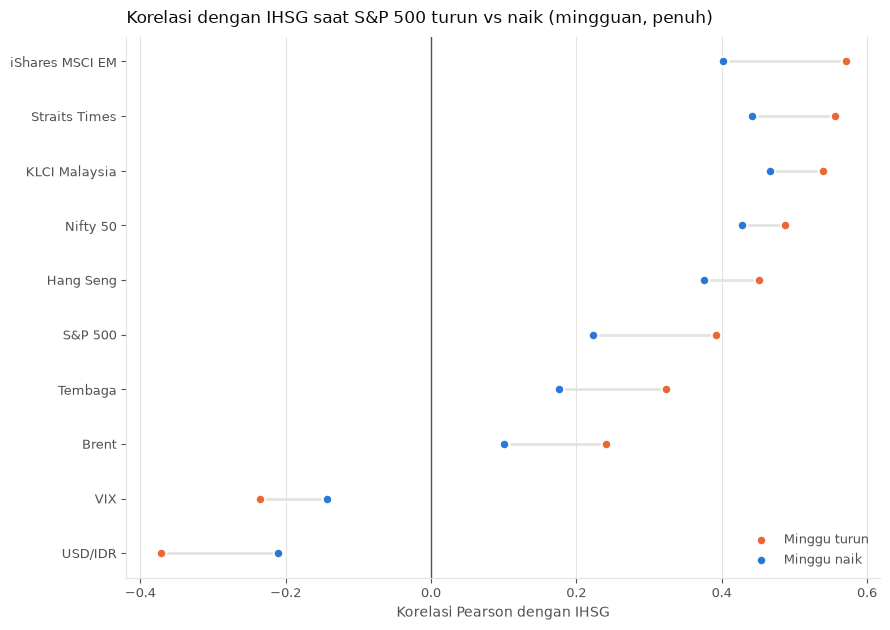

In [11]:
a_full = asym["penuh"]
spx_view = a_full[(a_full["kondisi"] == acfg["condition_ids"][0]) & (a_full["mode"] == "tanda")].set_index("id")
display(spx_view[["r_turun", "r_naik", "p_fisher_bh", "asimetri_berlebih", "ci_lo_boot", "ci_hi_boot", "p_boot_bh"]]
        .join(labels).round(3))
cond0 = names[acfg["condition_ids"][0]]
fig = plots.plot_asymmetric(spx_view.reset_index(), names,
                            f"Korelasi dengan IHSG saat {cond0} turun vs naik (mingguan, penuh)")

## 6. Matriks korelasi mingguan antar-seri Core (2010–2019)

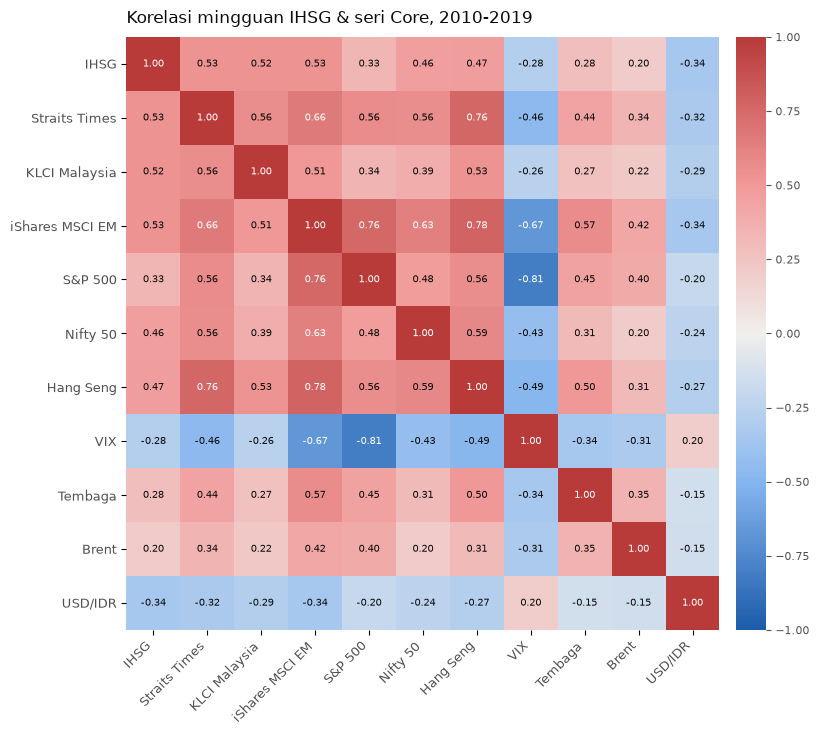

In [12]:
cmat = an.corr_matrix(weekly, [target_id] + core, scr_s, scr_e)
fig = plots.plot_corr_heatmap(cmat.rename(index=names, columns=names), "Korelasi mingguan IHSG & seri Core, 2010-2019")

## 7. Uji ulang hipotesis lama: "korelasi USD/IDR menguat dari 2010–2014 ke 2015–2019"

Hipotesis ini berasal dari screening dengan data mentah (−0,11 di 2010–2014 → −0,41 di 2015–2019). Bad tick Okt–Des 2013 jatuh di paruh **pertama**, dan bad tick seperti itu memperlemah korelasi. Pertanyaannya: dengan data bersih, apakah pola "menguat" itu masih ada?

Uji yang dipakai adalah Fisher z untuk selisih korelasi dua sub-periode yang tidak tumpang tindih.

In [13]:
prices_raw = load_prices(series["ticker"].tolist(), start=dec2["analysis_start"], end=cfg["project"]["end_date"],
                         verbose=False)
raw = close_panel(prices_raw, dict(zip(series["ticker"], series["id"])))
clean_old, _, _ = pp.clean_prices(prices_raw, series, cfg, fx_max_days=cfg["quality"]["fx_cleaning"]["max_reversal_days_old"])
variants = {"sebelum cleaning": pp.weekly_returns(raw, transforms),
            "aturan lama (<= 1 hari)": pp.weekly_returns(clean_old, transforms),
            "bersih (Amandemen 1)": weekly}
sub = an.subperiod_test(variants, target_id, fx_id, cfg["analysis"]["usdidr_subperiods"])
print("Sub-periode:", sub.attrs["subperiode"])
sub.round(3)

Sub-periode: 2010-2014 vs 2015-2019


,varian,r_awal,ci_awal,n_awal,r_akhir,ci_akhir,n_akhir,selisih,z_fisher,p_fisher
0,sebelum cleaning,-0.111,"(-0.23095938507692074, 0.011729039187859105)",255,-0.414,"(-0.5109907450276581, -0.306023133127499)",253,-0.302,3.679,0.000
1,aturan lama (<= 1 hari),-0.111,"(-0.23095938507692074, 0.011729039187859105)",255,-0.414,"(-0.5109907450276581, -0.306023133127499)",253,-0.302,3.679,0.000
2,bersih (Amandemen 1),-0.288,"(-0.39654344487109217, -0.1709144425568356)",255,-0.414,"(-0.5109907450276581, -0.306023133127499)",253,-0.126,1.614,0.107


## 8. Sensitivitas: USD/IDR harian dengan dan tanpa kuotasi basi

Ada 42 return harian IHSG–USD/IDR yang ditandai `flag_stale_quote` (Senin basi 2012–2013, lihat Phase 2). Return ini belum dibuang; keputusannya diambil sebelum Phase 4. Tabel ini menunjukkan seberapa besar pengaruhnya.

In [14]:
stale = an.stale_sensitivity(daily, fx_id, periods)
stale.round(4)

,periode,sampel,metode,n_flag,r,n,ci_lo,ci_hi,p
0,penuh,semua return,pearson,42,-0.1265,4757,-0.1544,-0.0984,0.0000
1,penuh,semua return,spearman,42,-0.1289,4757,-0.1576,-0.1001,0.0000
2,penuh,tanpa flag_stale_quote,pearson,42,-0.1352,4715,-0.1631,-0.1070,0.0000
3,penuh,tanpa flag_stale_quote,spearman,42,-0.1332,4715,-0.1620,-0.1042,0.0000
4,screening,semua return,pearson,42,-0.0715,2420,-0.1110,-0.0317,0.0004
5,screening,semua return,spearman,42,-0.1047,2420,-0.1451,-0.0639,0.0000
6,screening,tanpa flag_stale_quote,pearson,42,-0.0909,2378,-0.1307,-0.0509,0.0000
7,screening,tanpa flag_stale_quote,spearman,42,-0.1129,2378,-0.1536,-0.0719,0.0000
8,pasca,semua return,pearson,0,-0.1030,1637,-0.1507,-0.0548,0.0000
9,pasca,semua return,spearman,0,-0.1120,1637,-0.1610,-0.0625,0.0000


## 9. Simpan hasil

Semua tabel disimpan ke `reports/phase3/`.

In [15]:
ranks = an.rank_stability(tab)
tables = {"korelasi": tab, "korelasi_target_usd": tab_usd, "idr_vs_usd": usd_cmp, "sesi_harian_vs_mingguan": gap,
          "peringkat_abs_r": ranks, "asimetris_penuh": asym["penuh"], "asimetris_screening": asym["screening"],
          "matriks_korelasi_mingguan_screening": cmat, "usdidr_subperiode": sub, "usdidr_stale_sensitivitas": stale,
          "vif_screening": vif.to_frame(), "beta_satu_faktor_screening": one}
tables |= {f"regresi_faktor_{p}": r.join(labels) for p, r in regs.items()}
summary = {"target_id": target_id, "periode": periods, "model_regresi": models, "skenario_beta_screening": scenarios,
           "usdidr_subperiode": sub.drop(columns=["ci_awal", "ci_akhir"]).to_dict("records")}
paths = an.save_phase3_outputs(output_dir(cfg, "reports", "phase3"), tables, summary)
[p.name for p in paths]

['korelasi.csv',
 'korelasi_target_usd.csv',
 'idr_vs_usd.csv',
 'sesi_harian_vs_mingguan.csv',
 'peringkat_abs_r.csv',
 'asimetris_penuh.csv',
 'asimetris_screening.csv',
 'matriks_korelasi_mingguan_screening.csv',
 'usdidr_subperiode.csv',
 'usdidr_stale_sensitivitas.csv',
 'vif_screening.csv',
 'beta_satu_faktor_screening.csv',
 'regresi_faktor_penuh.csv',
 'regresi_faktor_screening.csv',
 'regresi_faktor_pasca.csv',
 'summary.json']

## Ringkasan insight

Dibangun otomatis dari hasil di atas.

In [16]:
display(Markdown(an.phase3_summary(tab, ranks, regs["screening"], models["screening"], scenarios, usd_cmp,
                                   asym["penuh"], sub, cfg, names)))

### Ringkasan Phase 3 (deskriptif, asosiasi in-sample)

- **Seri paling kuat** (korelasi mingguan 2010-2019): Straits Times +0.53, iShares MSCI EM +0.53, KLCI Malaysia +0.52.
- **Stabilitas urutan:** korelasi peringkat (Kendall tau) screening vs pasca = 0.56, screening vs penuh = 0.82. Tiga teratas pasca-2020: iShares MSCI EM, Nifty 50, Straits Times.
- **Efek kurs:** rupiah melemah 1% (USD/IDR naik 1%) → IHSG rata-rata -0.23% di minggu yang sama (CI 95% -0.42% s/d -0.04%), seri Core lain dikendalikan (R² model 2010-2019 = 0.43).
- **IHSG dalam USD vs rupiah** (rata-rata |r_usd| − |r_idr| mingguan, seri non-kurs): pasca +0.05 (lebih kuat dalam USD); penuh +0.01 (praktis sama); screening +0.01 (praktis sama).
- **Pasar turun vs naik (S&P 500):** korelasi IHSG +0.39 di minggu S&P 500 turun vs +0.22 saat naik; setelah dibandingkan dengan yang diharapkan dari distribusi normal, asimetri berlebih +0.18 (CI bootstrap -0.01 s/d +0.36; CI memuat nol, belum meyakinkan).
- **Pasar turun vs naik (iShares MSCI EM):** korelasi IHSG +0.52 di minggu iShares MSCI EM turun vs +0.30 saat naik; setelah dibandingkan dengan yang diharapkan dari distribusi normal, asimetri berlebih +0.23 (CI bootstrap +0.07 s/d +0.37; CI tidak memuat nol).
- **Hipotesis lama USD/IDR menguat (2010-2014 vs 2015-2019):** data mentah -0.11 → -0.41 (p = 0.000); data bersih -0.29 → -0.41 (p = 0.11). Pola tidak lagi signifikan dengan data bersih.